We are interested in studying the behaviours of the sampling/optimization algorithm if we are restrincting the map to pixels belonging to some noise regime. More specifically, we want to study the interesting case of pixels being in a regime where both sources of noise are significant.

The range of amplitude of the forward model for which both sources of noise are significant depends on the noise parameters $\sigma_m$ and $\sigma_a$.

We will be working with NNBMA based forward model and its associated scaler to normalize the theta parameters from the linear scale to the log scale with which the NN forward model is working.

In [39]:
import pandas as pd
import numpy as np
from beetroots.modelling.forward_maps.neural_network_approx import NeuralNetworkApprox
import matplotlib.pyplot as plt

## Loading necessary objects

In [74]:
SIZE_CLOUD = 64

path_cloud = (
    f"/home/ngoeman/Documents/beetroots/data/toycases/astro_toy_N{SIZE_CLOUD}.pkl"
)
df = pd.read_pickle(path_cloud)
df = df.set_index("idx")

Theta_true_linscale = df[["kappa", "P", "radm", "Avmax", "angle"]].to_numpy()

path_model = "/home/ngoeman/Documents/beetroots/data/models/"
model_name = "meudon_pdr_model_dense"

fixed_params = {  # must contain all the params in list_names of the Simulation object. Values are in linear scale.
    "kappa": None,
    "P": None,
    "radm": None,
    "Avmax": None,
    "angle": 0.0,
}
is_log_scale_params = (
    {  # defines the scale to work with for each param (either log or lin)
        "kappa": True,
        "P": True,
        "radm": True,
        "Avmax": True,
        "angle": False,
    }
)

list_lines_fit = [
    "co_v0_j4__v0_j3",
    "co_v0_j5__v0_j4",
    "co_v0_j6__v0_j5",
    "co_v0_j7__v0_j6",
    "co_v0_j8__v0_j7",
    "co_v0_j9__v0_j8",
    "co_v0_j10__v0_j9",
    "co_v0_j11__v0_j10",
    "co_v0_j12__v0_j11",
    "co_v0_j13__v0_j12",
]

scaler = pd.read_pickle(path_model + model_name + "/scaler.pickle")
scaler_mean = scaler.mean_
scaler_mean = np.concatenate([[0], scaler_mean])
scaler_scale = scaler.scale_
scaler_scale = np.concatenate([[1], scaler_scale])

fixed_params_scaled = {  # must contain all the params in list_names of the Simulation object. Values are in linear scale.
    "kappa": None,
    "P": None,
    "radm": None,
    "Avmax": None,
    "angle": 0.0,
}
fixed_params_scaled["angle"] = (fixed_params["angle"] - scaler_mean[-1]) / scaler_scale[
    -1
]

Theta_scaled = np.zeros_like(Theta_true_linscale)
for i, param in enumerate(zip(fixed_params.values(), is_log_scale_params.values())):
    value, is_log = param
    if is_log:
        Theta_scaled[:, i] = (
            np.log10(Theta_true_linscale[:, i]) - scaler_mean[i]
        ) / scaler_scale[i]
    else:
        Theta_scaled[:, i] = (
            Theta_true_linscale[:, i] - scaler_mean[i]
        ) / scaler_scale[i]

forward_map = NeuralNetworkApprox(
    path_model, model_name, fixed_params_scaled, device=None
)
forward_map.restrict_to_output_subset(list_lines_fit)

forward_evals_true = forward_map.evaluate(Theta_scaled)
log10_forward_evals_true = np.log10(forward_evals_true)

# df[list_lines_fit] = forward_evals_true

neural network runs on : cpu (asked: cpu)


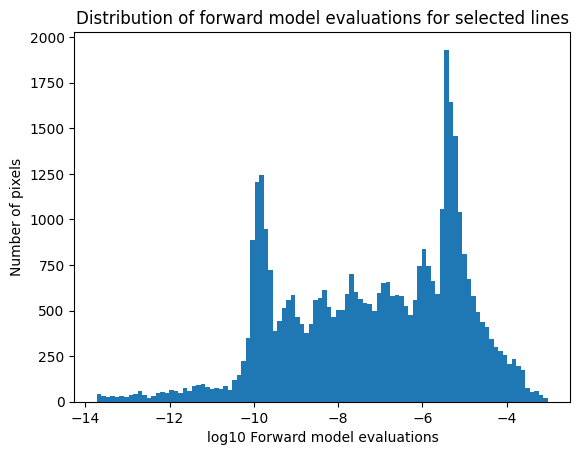

In [75]:
hist = plt.hist(log10_forward_evals_true.flatten(), bins=100)
plt.xlabel("log10 Forward model evaluations")
plt.ylabel("Number of pixels")
plt.title("Distribution of forward model evaluations for selected lines")
plt.show()

## Noise parameters

Here we define the intermediate regime where both sources of noise are significant through a parameter $k$. We consider the intermiadate regime to correspond to all values of $f(\theta)$ for which the ratio between both noise standard deviations is lower than $k$ (and greater than $1/k$). We then consider that if at least 50% of the lines of a pixel are in a the intermediate regime, then the pixel as whole is in the intermediate regime. 

### Version with fixing $k$

Interval intermediate regime: [ 2.5981978206883474e-10 ,  1.039279128275339e-09 ]
Number of pixels in intermediate regime: 177
Proportion of pixels in intermediate regime: 4.32 %
Ratio threshold: k = 2
Proportion of lines required to be in intermediate regime per pixel: 0.2


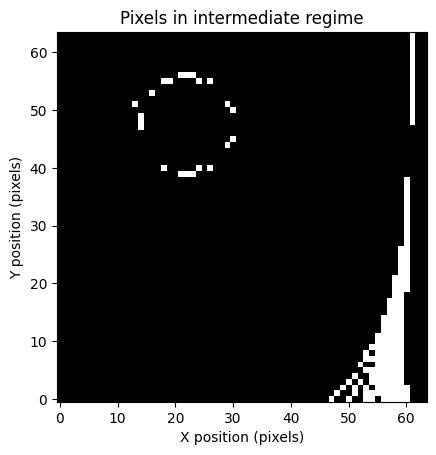

In [136]:
sigma_a = 1.38715e-10
sigma_m = np.log(1.3)

k = 2  # ratio threshold
max_intermediate = k * sigma_a / (np.exp(sigma_m**2) - 1) ** 0.5
min_intermediate = max_intermediate / k**2
prop = 0.2

is_intermediate = (forward_evals_true <= max_intermediate) & (
    forward_evals_true >= min_intermediate
)
is_pixel_intermediate = is_intermediate.mean(axis=1) >= prop

print("Interval intermediate regime: [", min_intermediate, ", ", max_intermediate, "]")
print("Number of pixels in intermediate regime:", is_pixel_intermediate.sum())
print(
    "Proportion of pixels in intermediate regime:",
    round(is_pixel_intermediate.mean() * 100, 2),
    "%",
)
print("Ratio threshold: k =", k)
print("Proportion of lines required to be in intermediate regime per pixel:", prop)

positions_intermediate = df.loc[is_pixel_intermediate, ["X", "Y"]].to_numpy()
image_selected = np.zeros((SIZE_CLOUD, SIZE_CLOUD))
image_selected[positions_intermediate[:, 1], positions_intermediate[:, 0]] = 1
plt.imshow(image_selected, origin="lower", cmap="gray")
plt.title("Pixels in intermediate regime")
plt.xlabel("X position (pixels)")
plt.ylabel("Y position (pixels)")
plt.show()

It seems that using the $k$ definition for the intermediate regime interval selects very few pixels. It is also difficult to finetune this $k$. We might try to use the $a_\ell$ parameters. I expect it to be much smaller as the width of these intervals is less than one full order. Nervetheless, the center of the interval might change a bit so the number of pixels that fall into the interval too. 

### Using $a_\ell$ parameters

Interval intermediate regime: [[2.74121348e-10 4.68278120e-09]
 [5.05895728e-10 2.06934196e-09]
 [2.76417704e-10 3.30531433e-09]
 [4.06638780e-10 2.33718553e-09]
 [2.14363623e-10 4.30632341e-09]
 [3.18646778e-10 2.74254482e-09]
 [2.41515060e-10 3.42422995e-09]
 [2.49859858e-10 2.93908689e-09]
 [3.71883323e-10 2.12049214e-09]
 [2.54177303e-10 3.46078656e-09]]
Number of pixels in intermediate regime: 71
Proportion of pixels in intermediate regime: 1.73 %
Ratio threshold: k = 2
Proportion of lines required to be in intermediate regime per pixel: 0.5


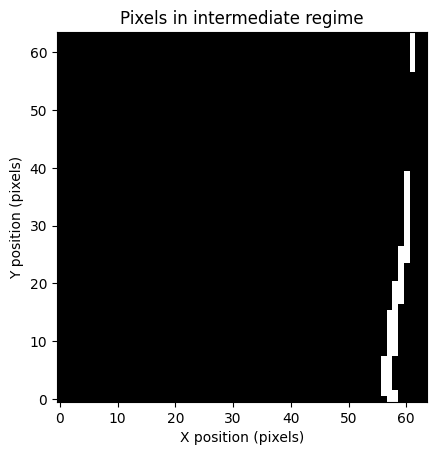

In [137]:
# Parameters for sigma_a = 1.38715e-10 and sigma_m = log(1.3)
a = np.array(
    [
        -8.945776637452402,
        0.6162805031816041,
        -8.990053362088656,
        0.3058856255217774,
        -9.01961068955661,
        0.5388234554026272,
        -9.011049008814007,
        0.379742197370109,
        -9.017371134426298,
        0.6514777772891878,
        -9.029268367431463,
        0.46742210084303515,
        -9.041246430572418,
        0.5758093521829035,
        -9.067045542703582,
        0.535257968520835,
        -9.051578315611764,
        0.37801498186142907,
        -9.027844208920843,
        0.5670190238876519,
    ]
).reshape(10, 2) * np.log(10)

a_c = a[:, 0]
a_r = a[:, 1]

sigma_a = 1.38715e-10
sigma_m = np.log(1.3)

min_intermediate = np.exp(a_c - a_r)
max_intermediate = np.exp(a_c + a_r)
prop = 0.5

is_intermediate = (forward_evals_true <= max_intermediate) & (
    forward_evals_true >= min_intermediate
)
is_pixel_intermediate = is_intermediate.mean(axis=1) >= prop

print(
    "Interval intermediate regime:",
    np.stack((min_intermediate, max_intermediate), axis=1),
)
print("Number of pixels in intermediate regime:", is_pixel_intermediate.sum())
print(
    "Proportion of pixels in intermediate regime:",
    round(is_pixel_intermediate.mean() * 100, 2),
    "%",
)
print("Ratio threshold: k =", k)
print("Proportion of lines required to be in intermediate regime per pixel:", prop)

positions_intermediate = df.loc[is_pixel_intermediate, ["X", "Y"]].to_numpy()
image_selected = np.zeros((SIZE_CLOUD, SIZE_CLOUD))
image_selected[positions_intermediate[:, 1], positions_intermediate[:, 0]] = 1
plt.imshow(image_selected, origin="lower", cmap="gray")
plt.title("Pixels in intermediate regime")
plt.xlabel("X position (pixels)")
plt.ylabel("Y position (pixels)")
plt.show()